# Chapter 5: Pretraining on Unlabeled Data


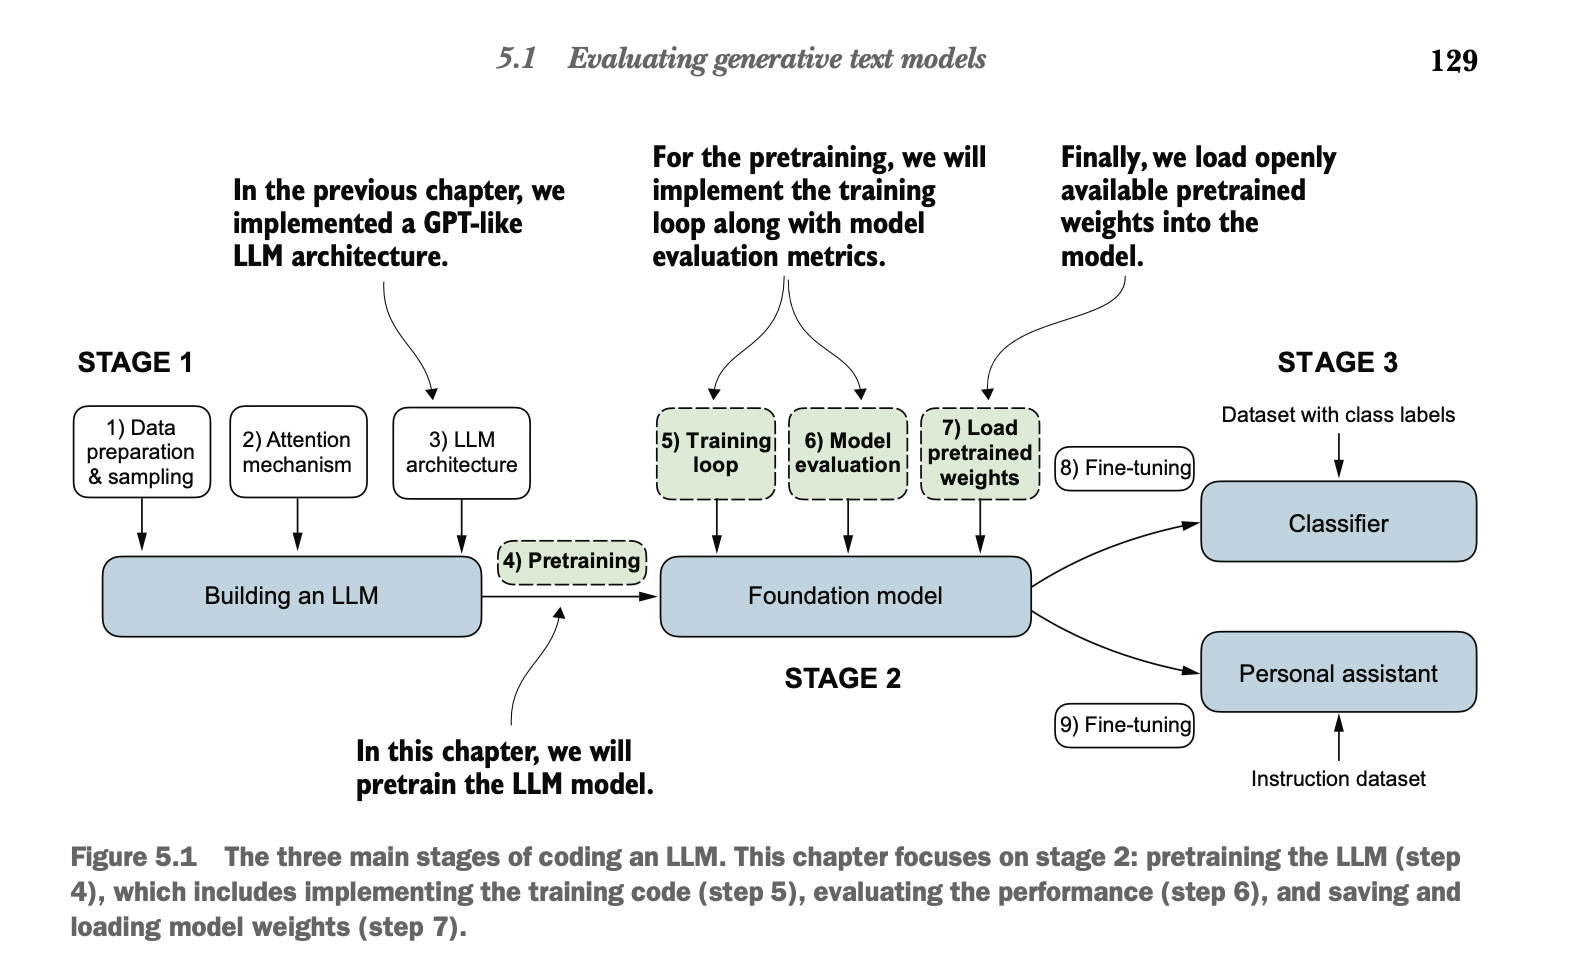


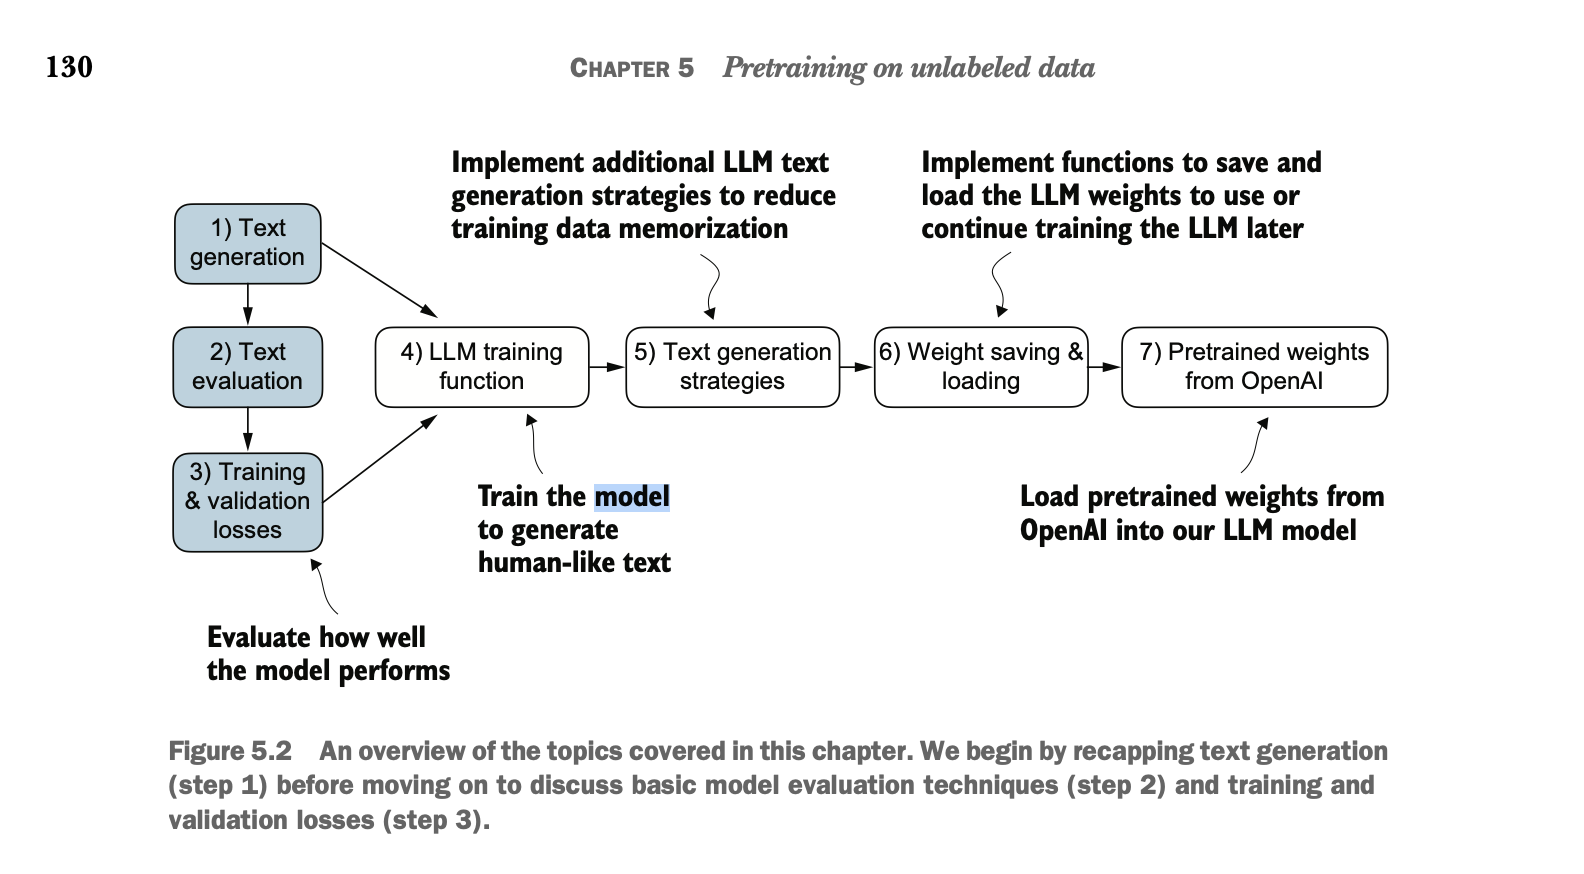


In [ ]:
import torch.nn as nn
import torch

from CH04_Implementing_a_GPT_model_from_scratch_to_generate_text.gpt import GPTModel

GPT_CONFIG_124M = {
    "vocab_size": 50257,
    "context_length": 256,
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.1,
    "qkv_bias": False,
}
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.eval()

Output text:
 Every effort moves you rentingetic wasnم refres RexMeCHicular stren


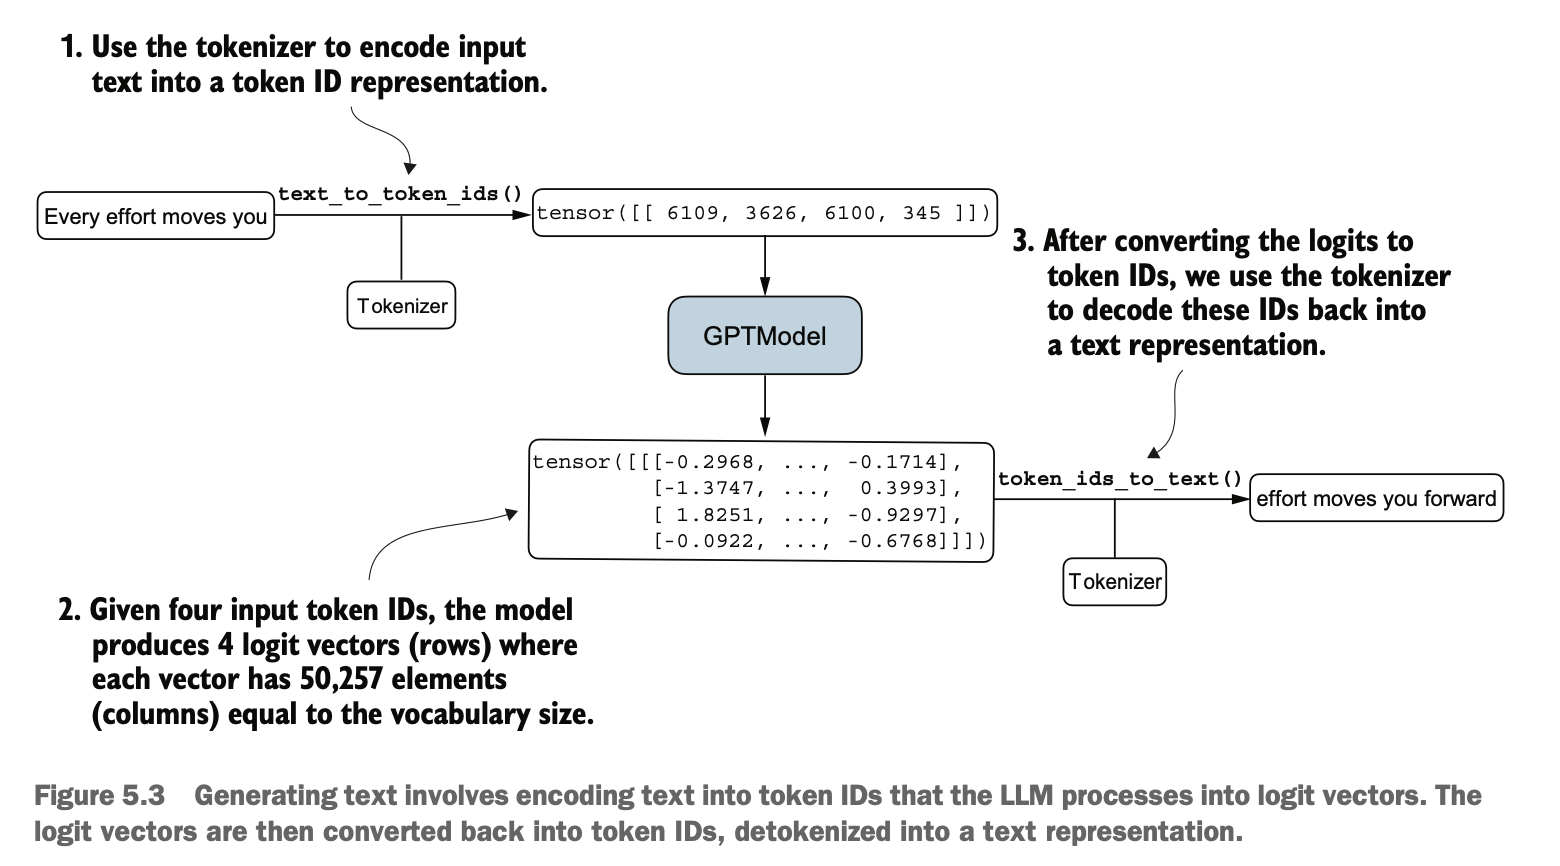


In [5]:
import tiktoken
from CH04_Implementing_a_GPT_model_from_scratch_to_generate_text.gpt import (
    generate_text_simple,
)
from CH04_Implementing_a_GPT_model_from_scratch_to_generate_text.gptPlaceholder import (
    GPT_CONFIG_124M,
)


def text_to_token_ids(text, tokenizer):
    encoded = tokenizer.encode(text, allowed_special={"<|endoftext|>"})

    # .unsqueeze(0) adds the batch dimension
    encoded_tensor = torch.tensor(encoded).unsqueeze(0)
    return encoded_tensor


def token_ids_to_text(token_ids, tokenizer):
    flat = token_ids.squeeze(0)  # Removes batch dimension
    return tokenizer.decode(flat.tolist())


start_context = "Every effort moves you"
tokenizer = tiktoken.get_encoding("gpt2")

token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids(start_context, tokenizer),
    max_new_tokens=10,
    context_size=GPT_CONFIG_124M["context_length"],
)
print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you rentingetic wasnم refres RexMeCHicular stren


# 5.1.2 Calculating the text generation loss

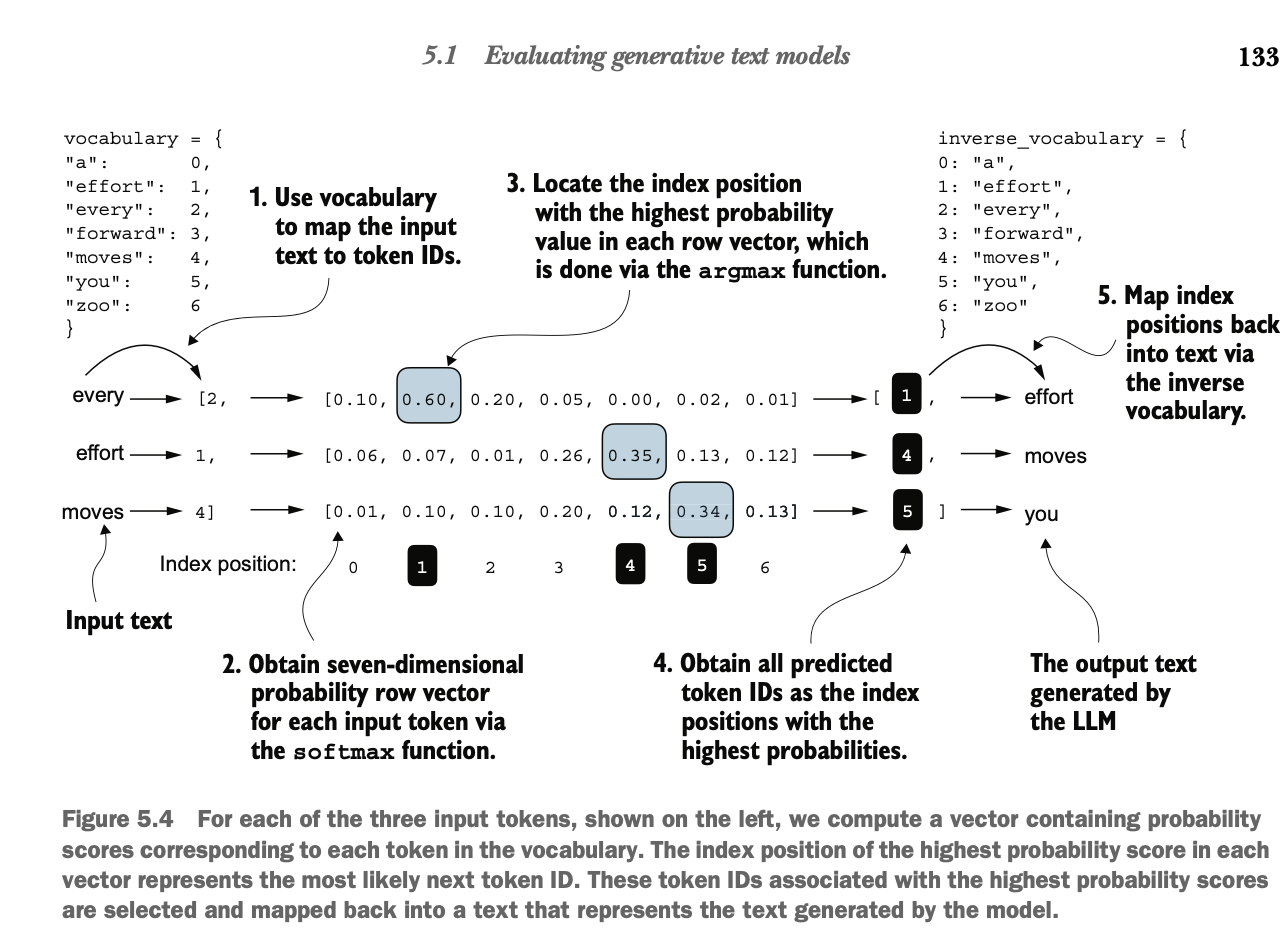